# Preprocessing

This notebook cleans the raw data and creates the train/validation/test split. It saves one file, `hotel_bookings_clean.csv`, which every group member uses for their model, so that all models are trained and tested on exactly the same data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hotels = pd.read_csv("hotel_bookings.csv")
print(f"Raw data: {hotels.shape[0]:,} bookings, {hotels.shape[1]} columns")

Raw data: 119,390 bookings, 32 columns


## 1. Remove columns recorded after booking

A model can only use what the hotel knows when the booking is made. These columns are filled in later, so using them would leak the answer into the model (data leakage):

* `reservation_status`, `reservation_status_date`: the outcome itself (Check-Out, Canceled or No-Show) and its date.
* `assigned_room_type`: rooms are assigned at check-in.
* `required_car_parking_spaces`: appears to be recorded on arrival.
* `booking_changes`, `days_in_waiting_list`: keep being updated until arrival or cancellation.

The check below shows how strongly two of them give the answer away.

In [2]:
room_changed = hotels.reserved_room_type != hotels.assigned_room_type
print(f"Cancellation rate, room changed at check-in: {hotels.is_canceled[room_changed].mean():.1%}")
print(f"Cancellation rate, parking space recorded:   {hotels.is_canceled[hotels.required_car_parking_spaces > 0].mean():.1%}")
print(f"Cancellation rate, all bookings:             {hotels.is_canceled.mean():.1%}")

leaky = ["reservation_status", "reservation_status_date", "assigned_room_type",
         "required_car_parking_spaces", "booking_changes", "days_in_waiting_list"]
df = hotels.drop(columns=leaky)

Cancellation rate, room changed at check-in: 5.4%
Cancellation rate, parking space recorded:   0.0%
Cancellation rate, all bookings:             37.0%


## 2. Missing values

* `agent` and `company` are IDs of the travel agent or company that made the booking. Missing almost certainly means *no* agent or company, not lost data, so we treat it as its own category rather than imputing.
* `company` is missing for 94% of bookings, and its IDs are too sparse to be useful, so we keep only a yes/no indicator, `has_company`.
* `country` (488 missing) becomes `"Unknown"`, and `children` (4 missing) becomes 0.

In [3]:
print(df.isna().sum()[lambda s: s > 0])

df["has_agent"] = df.agent.notna().astype(int)
df["agent"] = df.agent.fillna(0).astype(int).astype(str).replace("0", "none")
df["has_company"] = df.company.notna().astype(int)
df = df.drop(columns="company")
df["country"] = df.country.fillna("Unknown")
df["children"] = df.children.fillna(0).astype(int)

children         4
country        488
agent        16340
company     112593
dtype: int64


## 3. Remove invalid rows

We remove bookings that can't be real or can't be used:

* a negative price (1 booking) and a price of €5,400, more than ten times any other (1 booking);
* bookings with no guests (no adults, children or babies);
* bookings for zero nights, which never occupy a room;
* bookings whose market segment or distribution channel is `Undefined`.

Bookings with a price of exactly €0 are **kept**: they are mostly complimentary stays and are genuine bookings.

In [4]:
n_before = len(df)
invalid = ((df.adr < 0) | (df.adr > 1000)
           | (df.adults + df.children + df.babies == 0)
           | (df.stays_in_weekend_nights + df.stays_in_week_nights == 0)
           | (df.market_segment == "Undefined") | (df.distribution_channel == "Undefined"))
df = df[~invalid].copy()
print(f"Removed {n_before - len(df):,} invalid bookings; {len(df):,} remain")

Removed 832 invalid bookings; 118,558 remain


## 4. Tidy categories and add features

* `meal`: `Undefined` means the same as `SC` (no meal package), according to the [data paper](https://doi.org/10.1016/j.dib.2018.11.126), so we merge them.
* `country` and `agent` have 177 and 333 levels, many with only a handful of bookings. Levels with fewer than 100 bookings become `"Other"`, so that models don't fit noise in tiny groups. This uses only counts, never the target, so it doesn't leak information about cancellations.
* New features: `total_nights`, `total_guests`, and `arrival_date` (used for the split below).

In [5]:
df["meal"] = df.meal.replace("Undefined", "SC")

for col in ["country", "agent"]:
    counts = df[col].value_counts()
    df[col] = df[col].where(df[col].map(counts) >= 100, "Other")
    print(f"{col}: {df[col].nunique()} levels after grouping")

df["total_nights"] = df.stays_in_weekend_nights + df.stays_in_week_nights
df["total_guests"] = df.adults + df.children + df.babies
df["arrival_date"] = pd.to_datetime(
    df.arrival_date_year.astype(str) + "-" + df.arrival_date_month + "-"
    + df.arrival_date_day_of_month.astype(str), format="%Y-%B-%d")

country: 40 levels after grouping


agent: 86 levels after grouping


**Duplicates.** Almost 30% of the rows are exact copies of another row. Because identifiers were removed, we can't tell genuine repeat bookings (such as several identical rooms booked by one group) from duplicated records, so we **keep** them. The split below keeps all copies of a booking in the same set, so they can't leak from training into test.

In [6]:
print(f"Exact duplicate rows: {df.duplicated().sum():,} ({df.duplicated().mean():.0%})")

Exact duplicate rows: 34,213 (29%)


## 5. Train, validation and test split

We split the bookings **at random**, stratified by the target, into three sets:

| Set | Share | Used for |
| --- | --- | --- |
| Train | 70% | Fitting the models |
| Validation | 15% | Tuning hyperparameters and comparing settings |
| Test | 15% | Final evaluation, used once at the end |

**Why random?** The data runs from July 2015 to August 2017, and cancellation rates vary with the season (`01-Introduction`, Figure 5). Splitting by date would give each set a different mix of months: the last part of the data contains no autumn arrivals, for example. A random split gives every set roughly the same mix of seasons, hotels and years, so differences in scores reflect the models rather than the time of year.

**Why stratified?** Stratifying on `is_canceled` gives each set the same cancellation rate (37%), so no set is easier or harder by chance.

**Why keep copies together?** About 30% of rows have an exact copy elsewhere in the data (Section 4). With a plain random split, the check below shows that a third of test bookings would have an identical copy in the training set, so a model could score well by memorising rows rather than learning patterns. We therefore split *groups* of identical rows, so all copies land in the same set.

**Why a validation set?** Tuning a model on the test set would make its test score optimistic. Each member tunes on the validation set only, and scores the test set once, at the end.

**Limitation.** A random split measures how well a model predicts bookings like those it was trained on. It does not test whether a model trained on past bookings will predict *future* ones, where cancellation behaviour may have changed.

In [7]:
from sklearn.model_selection import train_test_split

# Rows that are exact copies of each other share a group id
group = pd.util.hash_pandas_object(df, index=False)

# How much would a plain random split leak?
naive_train, naive_test = train_test_split(group, test_size=0.15, random_state=42)
print(f"Plain random split: {naive_test.isin(set(naive_train)).mean():.0%} of test rows have an exact copy in training")

# Split the groups (not the rows), stratified by the target, 70 / 15 / 15
groups = pd.DataFrame({"group": group, "y": df.is_canceled}).drop_duplicates("group")
g_train, g_rest = train_test_split(groups, test_size=0.30, stratify=groups.y, random_state=42)
g_val, g_test = train_test_split(g_rest, test_size=0.50, stratify=g_rest.y, random_state=42)

df["split"] = "train"
df.loc[group.isin(set(g_val.group)), "split"] = "validation"
df.loc[group.isin(set(g_test.group)), "split"] = "test"

summary = df.groupby("split", sort=False).agg(bookings=("is_canceled", "size"),
                                              cancellation_rate=("is_canceled", "mean"),
                                              city_hotel_share=("hotel", lambda h: (h == "City Hotel").mean()))
summary["share"] = summary.bookings / len(df)
summary.style.format({"bookings": "{:,}", "cancellation_rate": "{:.1%}", "city_hotel_share": "{:.1%}",
                      "share": "{:.1%}"})

Plain random split: 34% of test rows have an exact copy in training


,bookings,cancellation_rate,city_hotel_share,share
split,,,,
train,"83,324",37.3%,66.8%,70.3%
test,"17,903",36.8%,67.7%,15.1%
validation,"17,331",37.5%,64.1%,14.6%


Figure 1 confirms that every set covers the whole year in similar proportions. The small differences (November, for example) come from moving whole groups of copies together.

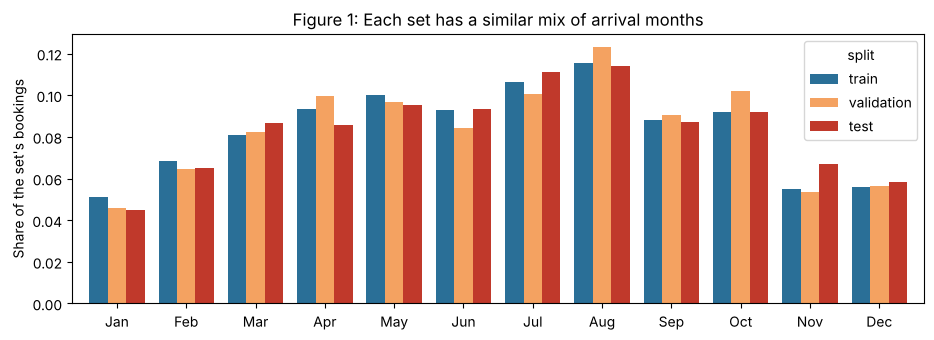

In [8]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
share = (df.groupby("split")["arrival_date_month"].value_counts(normalize=True)
           .unstack(0).reindex(months)[["train", "validation", "test"]])

ax = share.plot(kind="bar", figsize=(11, 3.5), color=["#2a6f97", "#f4a261", "#c0392b"], width=0.8)
ax.set_xticklabels([m[:3] for m in months], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Share of the set's bookings")
ax.set_title("Figure 1: Each set has a similar mix of arrival months")
plt.show()

## 6. Save the clean data

`arrival_date` and `arrival_date_year` are kept for reference, but they should **not** be used as model features. The hotel would apply the model to bookings in *future* years, which no model has seen, so anything it learns about specific years or dates would not carry over.

In [9]:
df = df.drop(columns="arrival_date_day_of_month")
df.to_csv("hotel_bookings_clean.csv", index=False)
print(f"Saved hotel_bookings_clean.csv: {df.shape[0]:,} bookings, {df.shape[1]} columns")
print(list(df.columns))

Saved hotel_bookings_clean.csv: 118,558 bookings, 30 columns
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'adr', 'total_of_special_requests', 'has_agent', 'has_company', 'total_nights', 'total_guests', 'arrival_date', 'split']


**Using the file in a model notebook:**

```python
df = pd.read_csv("hotel_bookings_clean.csv")
train, val, test = (df[df.split == s] for s in ["train", "validation", "test"])
```

Categorical columns are stored as text. Python models can one-hot encode them with `pd.get_dummies`; R models can use them as factors directly.